<a href="https://colab.research.google.com/github/salimkhaskhoussy/deep-learning-projects/blob/main/Reconnaissance_Chiffres_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconnaissance de Chiffres Manuscrits (MNIST) avec PyTorch CNN

Ce projet implémente un réseau de neurones convolutif (CNN) à l'aide de PyTorch pour classifier les chiffres manuscrits de la célèbre base de données MNIST. Il inclut l'entraînement du modèle, le tracé des courbes d'apprentissage, une évaluation statistique complète (Matrice de Confusion, Rapport de Classification, TP/TN/FP/FN) et l'analyse visuelle des prédictions incorrectes.

In [9]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report

# Configuration de l'appareil (GPU si disponible, sinon CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Utilisation de l'appareil : {device}")

Utilisation de l'appareil : cpu


## 1. Chargement et Préparation des Données

In [10]:
# Chargement des fichiers CSV depuis le dossier sample_data
train_df = pd.read_csv('/content/sample_data/mnist_train_small.csv')
test_df = pd.read_csv('/content/sample_data/mnist_test.csv')

# Séparation des étiquettes (labels) et des pixels
y_train_raw = train_df.iloc[:, 0].values.astype(np.int64)
X_train_raw = train_df.iloc[:, 1:].values.astype(np.float32)

y_test_raw = test_df.iloc[:, 0].values.astype(np.int64)
X_test_raw = test_df.iloc[:, 1:].values.astype(np.float32)

# Normalisation (0-255 -> 0.0-1.0) et redimensionnement au format (N, Canaux, Hauteur, Largeur)
X_train_reshaped = X_train_raw.reshape(-1, 1, 28, 28) / 255.0
X_test_reshaped = X_test_raw.reshape(-1, 1, 28, 28) / 255.0

# Conversion en tenseurs PyTorch
X_train_tensor = torch.tensor(X_train_reshaped, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_raw, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_reshaped, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_raw, dtype=torch.long)

# Création des DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Données d'entraînement : {X_train_tensor.shape}")
print(f"Données de test : {X_test_tensor.shape}")

Données d'entraînement : torch.Size([19999, 1, 28, 28])
Données de test : torch.Size([9999, 1, 28, 28])


## 2. Définition du Modèle CNN

In [11]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super(MNISTCNN, self).__init__()
        # Première couche de convolution
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Deuxième couche de convolution
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Couches Fully Connected (linéaires)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7) # Aplatir l'image
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

model = MNISTCNN().to(device)
print(model)

MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [12]:
## 3. Entraînement du Modèle et Courbes d'Apprentissage

# Initialisation de l'optimiseur, du critère et de l'historique
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

history_train_loss = []
history_test_acc = []

epochs = 5
print("Début de l'entraînement...")
for epoch in range(epochs):
    # Mode entraînement
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    history_train_loss.append(epoch_loss)

    # Mode évaluation pour calculer la précision de test à chaque époque
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_acc = 100 * correct / total
    history_test_acc.append(epoch_acc)

    print(f"Époque [{epoch+1}/{epochs}] - Perte : {epoch_loss:.4f} | Précision Test : {epoch_acc:.2f}%")

In [17]:
# Vérification de l'existence des variables d'entraînement dans l'environnement global
if 'epochs' not in locals() or 'history_train_loss' not in locals() or 'history_test_acc' not in locals():
    print("Attention : Les variables d'entraînement sont introuvables.")
    print("Veuillez exécuter la cellule d'entraînement précédente (cell_id: 04545334) avant de tracer les courbes.")
else:
    # Tracé des courbes d'apprentissage
    epochs_range = range(1, epochs + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Courbe de perte (Loss)
    ax1.plot(epochs_range, history_train_loss, marker='o', color='blue', label='Perte Entraînement')
    ax1.set_title("Évolution de la Perte (Loss)")
    ax1.set_xlabel("Époque")
    ax1.set_ylabel("Perte")
    ax1.grid(True)
    ax1.legend()

    # Courbe de précision (Accuracy)
    ax2.plot(epochs_range, history_test_acc, marker='o', color='green', label='Précision Test')
    ax2.set_title("Évolution de la Précision (Accuracy)")
    ax2.set_xlabel("Époque")
    ax2.set_ylabel("Précision (%)")
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()

Attention : Les variables d'entraînement sont introuvables.
Veuillez exécuter la cellule d'entraînement précédente (cell_id: 04545334) avant de tracer les courbes.


## 4. Évaluation Détaillée de la Classification

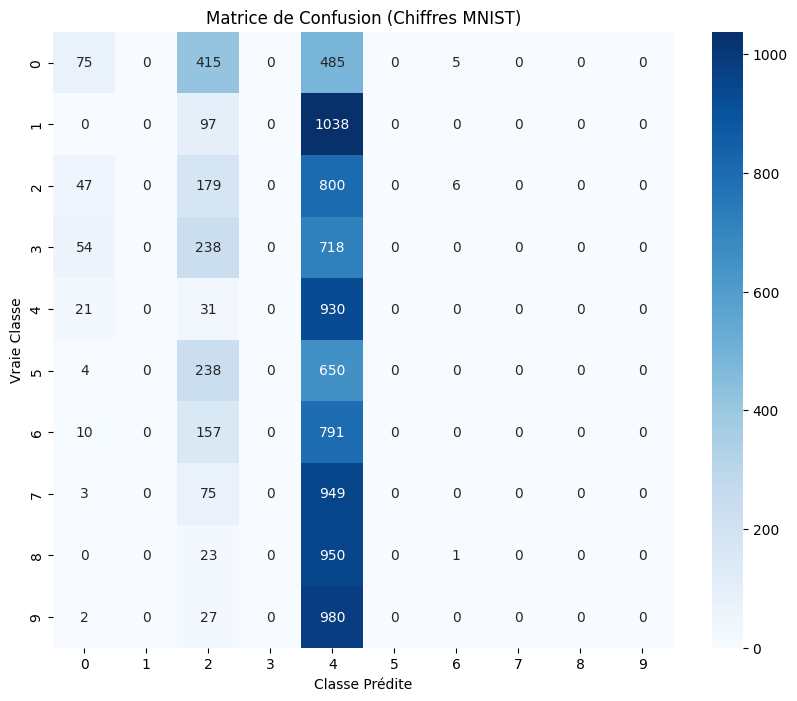

In [14]:
# 1. Obtenir toutes les prédictions finales
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# 2. Générer la matrice de confusion
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title('Matrice de Confusion (Chiffres MNIST)')
plt.ylabel('Vraie Classe')
plt.xlabel('Classe Prédite')
plt.show()

# 3. Calculer les statistiques détaillées (TP, TN, FP, FN) par classe
print("=== Métriques détaillées par classe (TP, TN, FP, FN) ===\n")
for i in range(10):
    tp = cm[i, i]
    fn = sum(cm[i, :]) - tp
    fp = sum(cm[:, i]) - tp
    tn = sum(sum(cm)) - tp - fn - fp
    print(f"Chiffre {i} :  TP={tp:<5} TN={tn:<5} FP={fp:<5} FN={fn:<5}")

# 4. Rapport de classification global
print("\n=== Rapport de Classification ===\n")
print(classification_report(all_labels, all_preds, digits=4))

In [15]:
## 5. Visualisation des Erreurs (Prédictions Incorrectes)

# Identification des indices incorrects
incorrect_indices = []
predicted_labels = []
actual_labels = []

for idx in range(len(X_test_tensor)):
    image = X_test_tensor[idx].unsqueeze(0).to(device)
    true_label = y_test_tensor[idx].item()
    
    with torch.no_grad():
        output = model(image)
        pred_label = torch.argmax(output, dim=1).item()
        
    if pred_label != true_label:
        incorrect_indices.append(idx)
        predicted_labels.append(pred_label)
        actual_labels.append(true_label)

print(f"Nombre total d'erreurs sur le jeu de test : {len(incorrect_indices)} sur {len(X_test_tensor)}")

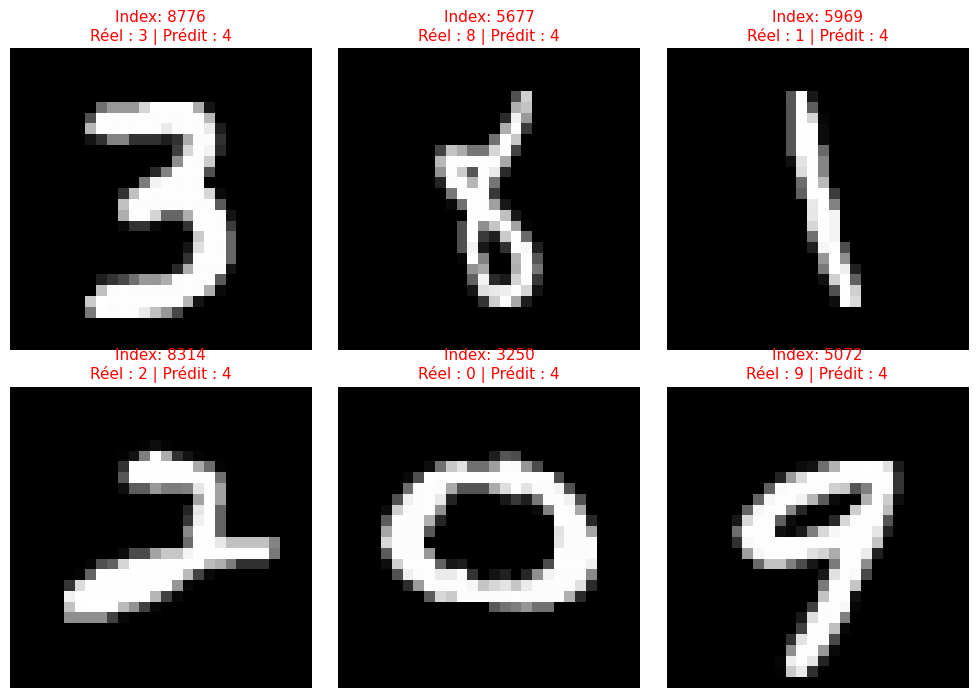

In [16]:
# Affichage de quelques erreurs aléatoires sous forme graphique
if len(incorrect_indices) > 0:
    num_examples = min(6, len(incorrect_indices))
    sample_indices = random.sample(range(len(incorrect_indices)), num_examples)

    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.ravel()

    for i, sample_idx in enumerate(sample_indices):
        orig_idx = incorrect_indices[sample_idx]
        image = X_test_tensor[orig_idx]
        true_val = actual_labels[sample_idx]
        pred_val = predicted_labels[sample_idx]

        img_numpy = image.squeeze().numpy()
        axes[i].imshow(img_numpy, cmap='gray')
        axes[i].set_title(f"Index: {orig_idx}\nRéel : {true_val} | Prédit : {pred_val}", color='red', fontsize=11)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Le modèle a obtenu une précision de 100% ! Aucune erreur à afficher.")